Notebook 9 — Volatility Regimes & Economic Significance


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import os
import glob
import itertools
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import accuracy_score, f1_score

import warnings
warnings.filterwarnings("ignore")

plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
})


Mounted at /content/drive


In [ ]:
PROJECT_PATH = "/content/drive/MyDrive/AI_Trading_Dissertation"
FINAL_PROJECT_PATH = PROJECT_PATH + "/Final_Project"

RESULTS_PATH = FINAL_PROJECT_PATH + "/04_Results"
PREDICTIONS_PATH = RESULTS_PATH + "/Predictions"
BENCHMARK_PATH = FINAL_PROJECT_PATH + "/02_Data/Processed/Benchmark"
FINAL_TABLES_PATH = RESULTS_PATH + "/Final_Tables"
FIGURES_PATH = FINAL_PROJECT_PATH + "/05_Figures"

os.makedirs(FINAL_TABLES_PATH, exist_ok=True)

LABELS = ["Buy", "Hold", "Sell"]
SIGNAL_TO_POSITION = {"Buy": 1, "Hold": 0, "Sell": -1}
PRIMARY_COST_BPS = 5

vix = pd.read_csv(os.path.join(BENCHMARK_PATH, "India_VIX_Daily.csv"), parse_dates=["date"])
vix = vix[["date", "close"]].rename(columns={"close": "vix"}).sort_values("date").reset_index(drop=True)

print(f"VIX: {len(vix)} daily observations, {vix['date'].min().date()} to {vix['date'].max().date()}")
print(f"VIX range: {vix['vix'].min():.2f} to {vix['vix'].max():.2f}, median {vix['vix'].median():.2f}")


VIX: 2621 daily observations, 2016-01-01 to 2026-07-31
VIX range: 9.15 to 83.61, median 15.11


---
# PART A — Volatility regimes
---

In [ ]:
pred_files = sorted(glob.glob(os.path.join(PREDICTIONS_PATH, "*_predictions.parquet")))
pred_files = [f for f in pred_files if "_dl_" not in os.path.basename(f) and "_tuned_" not in os.path.basename(f)]
stock_names = [os.path.basename(f).replace("_predictions.parquet", "") for f in pred_files]

print(f"Tree-model prediction files: {len(stock_names)}")


def attach_vix(df):
    out = df.copy()
    out["bar_date"] = pd.to_datetime(out["datetime"]).dt.normalize()
    out = pd.merge_asof(
        out.sort_values("bar_date"),
        vix.rename(columns={"date": "bar_date"}).sort_values("bar_date"),
        on="bar_date", direction="backward",
    )
    return out.sort_values("datetime").reset_index(drop=True)


_probe = attach_vix(pd.read_parquet(pred_files[0]))
print(f"\nBars with a VIX value attached: {_probe['vix'].notna().sum():,} / {len(_probe):,}")

VIX_SPLIT = _probe["vix"].median()
print(f"\nMedian VIX across the TEST period: {VIX_SPLIT:.2f}")
print("Bars at or above this are 'high volatility'; below are 'low volatility'.")
print("Using the test-window median (not the full 2016-2026 history) avoids")
print("conditioning the split on data outside the evaluation period.")


Tree-model prediction files: 10

Bars with a VIX value attached: 14,489 / 14,489

Median VIX across the TEST period: 13.72
Bars at or above this are 'high volatility'; below are 'low volatility'.
Using the test-window median (not the full 2016-2026 history) avoids
conditioning the split on data outside the evaluation period.


### Classification performance by regime

In [ ]:
MODELS = ["Baseline_Random", "Baseline_Momentum", "RandomForest", "XGBoost"]

regime_rows = []

for stock in stock_names:
    df = attach_vix(pd.read_parquet(os.path.join(PREDICTIONS_PATH, f"{stock}_predictions.parquet")))
    df = df.dropna(subset=["vix"])
    df["regime"] = np.where(df["vix"] >= VIX_SPLIT, "High VIX", "Low VIX")

    for model in MODELS:
        col = f"pred_{model}"
        if col not in df.columns:
            continue
        for regime, sub in df.groupby("regime"):
            regime_rows.append({
                "Stock": stock, "Model": model, "Regime": regime,
                "N_Bars": len(sub),
                "Accuracy": accuracy_score(sub["target_signal"], sub[col]),
                "F1_Macro": f1_score(sub["target_signal"], sub[col],
                                     average="macro", labels=LABELS, zero_division=0),
                "Mean_VIX": sub["vix"].mean(),
            })

regime_df = pd.DataFrame(regime_rows)
regime_df.to_csv(os.path.join(RESULTS_PATH, "Regime_Classification.csv"), index=False)

summary = (
    regime_df.groupby(["Model", "Regime"])[["Accuracy", "F1_Macro", "Mean_VIX"]]
    .mean().round(4).unstack()
)
print("Classification performance by volatility regime (mean across 10 stocks):\n")
display(summary)


Classification performance by volatility regime (mean across 10 stocks):



Accuracy         F1_Macro         Mean_VIX         
Regime            High VIX Low VIX High VIX Low VIX High VIX  Low VIX
Model                                                                
Baseline_Momentum   0.3404  0.3378   0.2816  0.2813  16.4368  12.0464
Baseline_Random     0.3377  0.3403   0.3338  0.3350  16.4368  12.0464
RandomForest        0.3889  0.3986   0.3787  0.3836  16.4368  12.0464
XGBoost             0.3877  0.3908   0.3778  0.3652  16.4368  12.0464

In [ ]:
# Is the regime difference statistically meaningful? Paired across the 10 stocks.
print("Paired test: does F1 differ between high- and low-VIX regimes?\n")

for model in MODELS:
    sub = regime_df[regime_df["Model"] == model]
    hi = sub[sub["Regime"] == "High VIX"].set_index("Stock")["F1_Macro"]
    lo = sub[sub["Regime"] == "Low VIX"].set_index("Stock")["F1_Macro"]
    common = hi.index.intersection(lo.index)
    hi, lo = hi[common].values, lo[common].values

    if len(hi) < 3 or np.allclose(hi - lo, 0):
        continue

    stat, p = stats.wilcoxon(hi, lo)
    d = (hi - lo).mean() / (hi - lo).std(ddof=1) if (hi - lo).std(ddof=1) > 0 else np.nan
    direction = "better in HIGH volatility" if (hi - lo).mean() > 0 else "better in LOW volatility"
    flag = "significant" if p < 0.05 else "not significant"

    print(f"  {model:20s} high {hi.mean():.4f}  low {lo.mean():.4f}  "
          f"diff {(hi-lo).mean():+.4f}  p={p:.4f}  d={d:+.2f}  -> {direction} ({flag})")


Paired test: does F1 differ between high- and low-VIX regimes?

  Baseline_Random      high 0.3338  low 0.3350  diff -0.0012  p=0.6250  d=-0.12  -> better in LOW volatility (not significant)
  Baseline_Momentum    high 0.2816  low 0.2813  diff +0.0003  p=0.9219  d=+0.04  -> better in HIGH volatility (not significant)
  RandomForest         high 0.3787  low 0.3836  diff -0.0048  p=0.4922  d=-0.25  -> better in LOW volatility (not significant)
  XGBoost              high 0.3778  low 0.3652  diff +0.0125  p=0.0840  d=+0.72  -> better in HIGH volatility (not significant)


### Trading performance by regime

Classification is only half the question — the same split applied to actual returns.

In [ ]:

def backtest_slice(close, positions, cost_bps):
    close = pd.Series(np.asarray(close, dtype=float))
    mkt = close.pct_change()
    pos = pd.Series(positions).shift(1).fillna(0)
    turn = pos.diff().abs().fillna(pos.abs())
    net = pos * mkt - turn * (cost_bps / 10000.0)
    net = net[mkt.notna()]
    if len(net) == 0:
        return np.nan, np.nan
    return float((1 + net).cumprod().iloc[-1] - 1), float(turn.sum())


trade_regime_rows = []

for stock in stock_names:
    df = attach_vix(pd.read_parquet(os.path.join(PREDICTIONS_PATH, f"{stock}_predictions.parquet")))
    df = df.dropna(subset=["vix"]).reset_index(drop=True)
    df["regime"] = np.where(df["vix"] >= VIX_SPLIT, "High VIX", "Low VIX")

    for model in ["RandomForest", "XGBoost"]:
        col = f"pred_{model}"
        if col not in df.columns:
            continue
        for regime, sub in df.groupby("regime"):
            sub = sub.reset_index(drop=True)
            positions = sub[col].map(SIGNAL_TO_POSITION).fillna(0).values
            ret, turn = backtest_slice(sub["close"].values, positions, PRIMARY_COST_BPS)
            bh = sub["close"].iloc[-1] / sub["close"].iloc[0] - 1
            trade_regime_rows.append({
                "Stock": stock, "Model": model, "Regime": regime,
                "Return": ret, "BuyHold": bh, "Turnover": turn, "N_Bars": len(sub),
            })

trade_regime = pd.DataFrame(trade_regime_rows)
trade_regime.to_csv(os.path.join(RESULTS_PATH, "Regime_Trading.csv"), index=False)

trade_summary = (
    trade_regime.groupby(["Model", "Regime"])[["Return", "BuyHold", "Turnover"]]
    .mean().round(4).unstack()
)
print(f"Trading performance by regime (every-bar variant, {PRIMARY_COST_BPS} bps):\n")
display(trade_summary)


Trading performance by regime (every-bar variant, 5 bps):



Return          BuyHold         Turnover        
Regime       High VIX Low VIX High VIX Low VIX High VIX Low VIX
Model                                                          
RandomForest  -0.5595 -0.5948  -0.0493 -0.0403   2309.0  2368.3
XGBoost       -0.7218 -0.7127  -0.0493 -0.0403   2907.6  2857.8

### FIGURE: regime comparison

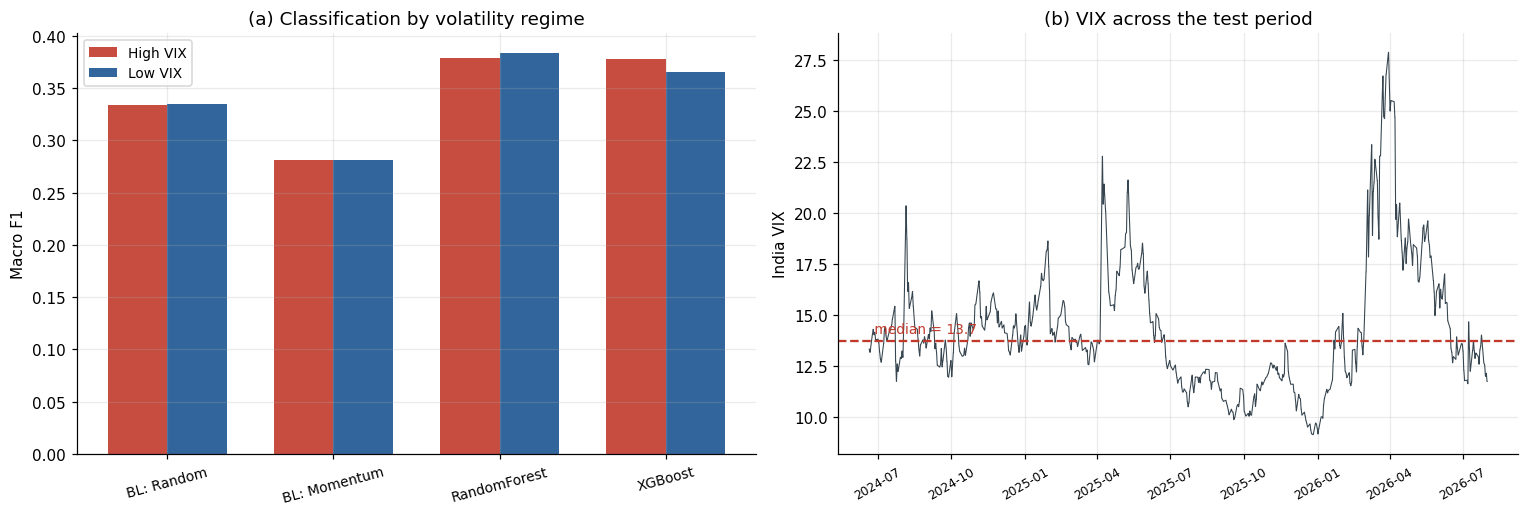

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

ax = axes[0]
plot_models = [m for m in MODELS if m in regime_df["Model"].unique()]
x = np.arange(len(plot_models)); w = 0.36
hi_vals = [regime_df[(regime_df.Model == m) & (regime_df.Regime == "High VIX")]["F1_Macro"].mean() for m in plot_models]
lo_vals = [regime_df[(regime_df.Model == m) & (regime_df.Regime == "Low VIX")]["F1_Macro"].mean() for m in plot_models]

ax.bar(x - w/2, hi_vals, w, label="High VIX", color="#c0392b", alpha=0.9)
ax.bar(x + w/2, lo_vals, w, label="Low VIX", color="#1a5490", alpha=0.9)
ax.set_xticks(x)
ax.set_xticklabels([m.replace("Baseline_", "BL: ") for m in plot_models], fontsize=9, rotation=15)
ax.set_ylabel("Macro F1")
ax.set_title("(a) Classification by volatility regime")
ax.legend(fontsize=9)

ax = axes[1]
d = _probe.dropna(subset=["vix"])
ax.plot(pd.to_datetime(d["datetime"]), d["vix"], linewidth=0.7, color="#36454F")
ax.axhline(VIX_SPLIT, color="#c0392b", linestyle="--", linewidth=1.5)
ax.text(pd.to_datetime(d["datetime"]).iloc[10], VIX_SPLIT + 0.4,
        f" median = {VIX_SPLIT:.1f}", color="#c0392b", fontsize=9)
ax.set_ylabel("India VIX")
ax.set_title("(b) VIX across the test period")
ax.tick_params(axis="x", rotation=30, labelsize=8)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_PATH, "fig8_volatility_regimes.png"), dpi=200, bbox_inches="tight")
plt.show()


---
# PART B — Is the economic ranking statistically real?
---

In [ ]:
def load_returns_by_stock():
    """Per-stock thresholded returns at the primary cost level, for every model."""s
    frames = []

    thr = os.path.join(RESULTS_PATH, "Backtest_Thresholded_Test.csv")
    if os.path.exists(thr):
        d = pd.read_csv(thr)
        d = d[d["Cost_BPS"] == PRIMARY_COST_BPS][["Stock", "Model", "Total_Return"]]
        frames.append(d)

    for run in ["v2", "v1"]:
        p = os.path.join(RESULTS_PATH, f"Backtest_DL_Full_{run}.csv")
        if os.path.exists(p):
            d = pd.read_csv(p)
            d = d[(d["Cost_BPS"] == PRIMARY_COST_BPS) & (d["Variant"] == "Thresholded")]
            frames.append(d[["Stock", "Model", "Total_Return"]])
            print(f"included deep learning run {run}")
            break

    return pd.concat(frames, ignore_index=True)


rets = load_returns_by_stock()
paired_ret = rets.pivot_table(index="Stock", columns="Model", values="Total_Return").dropna(axis=1)

print(f"\nModels with returns on all {len(paired_ret)} stocks: {list(paired_ret.columns)}\n")
display((paired_ret * 100).round(2))


included deep learning run v2

Models with returns on all 10 stocks: ['LSTM', 'RandomForest', 'Transformer', 'XGBoost']



Model,LSTM,RandomForest,Transformer,XGBoost
Stock,,,,
Eicher_Motors,-5.73,-8.80,8.76,-10.88
HDFCB,-0.89,-5.45,0.00,-37.54
Hindustan_Unilever,-39.30,9.81,-4.92,-47.05
ICICIBC,-0.19,0.00,0.00,-37.75
INFOSYS,4.57,-14.84,-13.18,-37.49
ITC,-4.62,-12.02,-24.52,-45.54
Mahindra_and_Mahindra,0.00,5.38,0.00,-53.28
ONGC,0.00,-28.93,0.00,-10.90
Reliance,-18.54,-10.56,-1.57,-50.49


In [ ]:
def holm(pvals):
    p = np.asarray(pvals, dtype=float); n = len(p)
    order = np.argsort(p); adj = np.empty(n); run = 0.0
    for rank, idx in enumerate(order):
        run = max(run, (n - rank) * p[idx]); adj[idx] = min(run, 1.0)
    return adj


rows = []
for m1, m2 in itertools.combinations(paired_ret.columns, 2):
    a, b = paired_ret[m1].values, paired_ret[m2].values
    diff = a - b
    if np.allclose(diff, 0):
        continue
    try:
        _, wp = stats.wilcoxon(a, b)
    except ValueError:
        wp = np.nan
    sd = diff.std(ddof=1)
    rows.append({
        "Model_A": m1, "Model_B": m2,
        "Mean_A_%": round(a.mean() * 100, 2), "Mean_B_%": round(b.mean() * 100, 2),
        "Diff_pp": round(diff.mean() * 100, 2),
        "A_wins": int((diff > 0).sum()),
        "Wilcoxon_p": round(wp, 5) if not np.isnan(wp) else np.nan,
        "Cohens_d": round(diff.mean() / sd, 3) if sd > 0 else np.nan,
    })

ret_tests = pd.DataFrame(rows)
ret_tests["p_holm"] = holm(ret_tests["Wilcoxon_p"].fillna(1.0)).round(5)
ret_tests["Significant"] = ret_tests["p_holm"] < 0.05
ret_tests = ret_tests.sort_values("p_holm").reset_index(drop=True)

ret_tests.to_csv(os.path.join(FINAL_TABLES_PATH, "Table10_Return_Significance.csv"), index=False)
print("Pairwise comparison of thresholded returns:\n")
display(ret_tests)


Pairwise comparison of thresholded returns:



,Model_A,Model_B,Mean_A_%,Mean_B_%,Diff_pp,A_wins,Wilcoxon_p,Cohens_d,p_holm,Significant
0,LSTM,XGBoost,-7.03,-40.49,33.46,10,0.00195,1.641,0.01170,True
1,Transformer,XGBoost,-5.92,-40.49,34.57,10,0.00195,2.349,0.01170,True
2,RandomForest,XGBoost,-9.83,-40.49,30.66,9,0.00586,1.304,0.02344,True
3,LSTM,RandomForest,-7.03,-9.83,2.80,6,0.55664,0.126,1.00000,False
4,RandomForest,Transformer,-9.83,-5.92,-3.91,3,0.42578,-0.294,1.00000,False
5,LSTM,Transformer,-7.03,-5.92,-1.11,3,1.00000,-0.064,1.00000,False


In [ ]:
print("THE COMPARISON THAT MATTERS\n")

target = ret_tests[
    ((ret_tests.Model_A == "Transformer") & (ret_tests.Model_B == "RandomForest")) |
    ((ret_tests.Model_A == "RandomForest") & (ret_tests.Model_B == "Transformer"))
]

if len(target):
    r = target.iloc[0]
    print(f"  {r['Model_A']} ({r['Mean_A_%']}%) vs {r['Model_B']} ({r['Mean_B_%']}%)")
    print(f"  difference {r['Diff_pp']:+.2f} pp | {r['Model_A']} wins on {r['A_wins']}/10 stocks")
    print(f"  Wilcoxon p = {r['Wilcoxon_p']}, Holm-corrected {r['p_holm']}, Cohen's d = {r['Cohens_d']}")
    print()
    if r["Significant"]:
        print("  -> SIGNIFICANT. You may state that one outperformed the other economically.")
    else:
        print("  -> NOT SIGNIFICANT. State the ranking as observed but not established:")
        print('     "The Transformer achieved the highest break-even cost, though the')
        print('      difference from Random Forest was not statistically significant')
        print('      across ten stocks."')
else:
    print("  Transformer / RandomForest pair unavailable - check that Notebook 08 ran.")


THE COMPARISON THAT MATTERS

  RandomForest (-9.83%) vs Transformer (-5.92%)
  difference -3.91 pp | RandomForest wins on 3/10 stocks
  Wilcoxon p = 0.42578, Holm-corrected 1.0, Cohen's d = -0.294

  -> NOT SIGNIFICANT. State the ranking as observed but not established:
     "The Transformer achieved the highest break-even cost, though the
      difference from Random Forest was not statistically significant
      across ten stocks."


## STEP — Final summary

In [ ]:
lines = ["=" * 76, "REGIME & SIGNIFICANCE SUMMARY", "=" * 76, ""]

lines.append(f"VOLATILITY REGIMES  (split at test-period median VIX = {VIX_SPLIT:.2f})")
for model in MODELS:
    sub = regime_df[regime_df["Model"] == model]
    if len(sub) == 0:
        continue
    hi = sub[sub.Regime == "High VIX"]["F1_Macro"].mean()
    lo = sub[sub.Regime == "Low VIX"]["F1_Macro"].mean()
    lines.append(f"  {model:20s} high-VIX F1 {hi:.4f}   low-VIX F1 {lo:.4f}   diff {hi-lo:+.4f}")

lines += ["", "ECONOMIC SIGNIFICANCE  (thresholded returns, paired across 10 stocks)"]
n_sig = int(ret_tests["Significant"].sum())
lines.append(f"  {n_sig} of {len(ret_tests)} pairwise comparisons significant after Holm correction")
for _, r in ret_tests.head(5).iterrows():
    mark = "*" if r["Significant"] else " "
    lines.append(f"  {mark} {r['Model_A']:18s} vs {r['Model_B']:18s} "
                 f"diff {r['Diff_pp']:+6.2f}pp  p_holm {r['p_holm']:.4f}")

lines += ["", "=" * 76]

txt = "\n".join(lines)
print(txt)
with open(os.path.join(FINAL_TABLES_PATH, "REGIME_SIGNIFICANCE_SUMMARY.txt"), "w") as f:
    f.write(txt)


REGIME & SIGNIFICANCE SUMMARY

VOLATILITY REGIMES  (split at test-period median VIX = 13.72)
  Baseline_Random      high-VIX F1 0.3338   low-VIX F1 0.3350   diff -0.0012
  Baseline_Momentum    high-VIX F1 0.2816   low-VIX F1 0.2813   diff +0.0003
  RandomForest         high-VIX F1 0.3787   low-VIX F1 0.3836   diff -0.0048
  XGBoost              high-VIX F1 0.3778   low-VIX F1 0.3652   diff +0.0125

ECONOMIC SIGNIFICANCE  (thresholded returns, paired across 10 stocks)
  3 of 6 pairwise comparisons significant after Holm correction
  * LSTM               vs XGBoost            diff +33.46pp  p_holm 0.0117
  * Transformer        vs XGBoost            diff +34.57pp  p_holm 0.0117
  * RandomForest       vs XGBoost            diff +30.66pp  p_holm 0.0234
    LSTM               vs RandomForest       diff  +2.80pp  p_holm 1.0000
    RandomForest       vs Transformer        diff  -3.91pp  p_holm 1.0000

